Лабораторная работа 3. Пользовательские функции ФИО студента:Панченко А.И

Группа студента:инб-о-26-2

Вариант: 13
Задание:В файле data
_
v1.txt найдите самую длинную подпоследовательность
не содержащую прописных букв и цифр, кратных 4. В ответе
укажите саму подпоследовательность и ее длину.
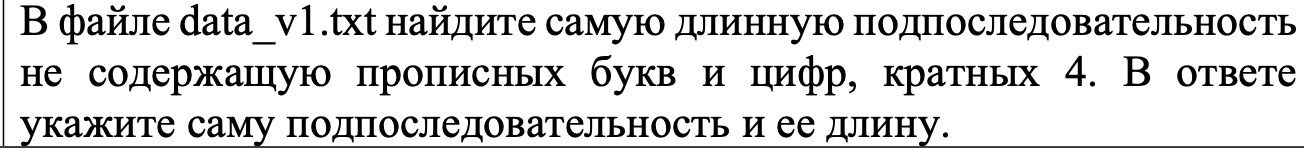

Опишите назначение, сходства и различия функций чтения из
текстового файла: read( ), readline( ), readlines( ).
2. как прочитать многострочный текстовый файл не используя явно
методы read( ), readline( ), readlines( )?
3. Какова задача закрытия файла?
4. Что такое позиция считывания файла? Где первоначально находится
позиция считывания при открытии файла ввода?
5. В каком режиме открывается файл, если требуется записать в него
данные, но при этом требуется оставить существующее содержимое файла
нетронутым? В какую часть файла данные записываются при этом?
6. Дайте краткое объяснение, что такое исключение.
7. обрабатывает инструкцией try/except?
Что происходит, если вызвано исключение, и программа его не
8. Какое исключение программа вызывает, когда она пытается открыть
несуществующий файл?
25
9. Какое исключение программа вызывает, когда она применяет функцию
float( ) для конвертации нечислового строкового значения в число?
10. Что происходит, если файл не существует и программа пытается его
открыть в режиме дозаписи?
Ответы:
1. Функции чтения: read(), readline(), readlines()
Все три метода используются для чтения данных из открытого текстового файла, но возвращают их в разном формате и объеме:• Сходство: Все три метода считывают данные, сдвигают внутренний указатель (позицию чтения) вперед и возвращают пустую строку (или пустой список), если файл закончился.
• Различия: read() и readline() возвращают строку, а readlines() — список. read() и readlines() читают файл до конца, а readline() — только до ближайшего переноса строки.

2. Чтение файла без явного использования read/readline/readlines
Для этого объект файла используют как итератор в цикле for. Это самый эффективный и современный способ в Python, так как строки считываются в память поочередно (буферизованно), что экономит оперативную память

3. Задача закрытия файла
Закрывать файл (методом file.close() или автоматически через контекстный менеджер with) необходимо для:
• Сохранения данных: Запись в файл часто буферизуется (сначала данные копятся в оперативной памяти). При закрытии принудительно происходит сброс буфера (flush) на диск.
• Освобождения ресурсов: Операционная система выделяет на каждый открытый файл системные ресурсы и дескрипторы. Их количество ограничено.
• Снятия блокировки: В некоторых ОС открытый файл нельзя удалить, переместить или открыть в другой программе, пока он не закрыт.

4. Позиция считывания файла
• Позиция считывания (указатель файла) — это виртуальный маркер (число в байтах), который показывает, с какого места в файле начнется следующее чтение или запись. Каждое чтение сдвигает этот указатель вперед.
• При открытии файла в режиме ввода ("r") указатель первоначально находится в самом начале файла (позиция 0), перед первым символом.

5. Режим сохранения старых данных при записи
• Для этого используется режим дозаписи ("a" — append).
• Данные при этом записываются строго в самый конец файла, добавляясь к уже существующему тексту.

6. Что такое исключение
Исключение (Exception) — это возникающий во время выполнения программы сбой или ошибка (например, деление на ноль или отсутствие файла), которая прерывает нормальный ход работы программы и передает управление специальным обработчикам.

7. Что происходит, если исключение не обработано в try/except
Если программа не перехватывает возникшее исключение:
1. Выполнение текущего кода аварийно прерывается.
2. В консоль выводится Traceback (информация о цепочке вызовов, типе ошибки и строке, где она произошла).
3. Программа завершает свою работу с ненулевым кодом ошибки.

8. Исключение при открытии несуществующего файла

Вызывается исключение FileNotFoundError (в старых версиях Python или как базовый класс — IOError).

9. Исключение при конвертации нечисловой строки через float()

Вызывается исключение ValueError (ошибка значения, так как тип данных верный — строка, но её содержимое нельзя превратить в число с плавающей точкой).

10. Открытие несуществующего файла в режиме дозаписи ("a")
Если файла не существует, Python не выдаст ошибку, а автоматически создаст новый пустой файл с таким именем в указанной директории и приготовится записывать данные в него.

In [1]:
def find_longest_substring(filename):
    try:
        with open(filename, 'r', encoding='utf-8') as file:
            text = file.read()
    except FileNotFoundError:
        return "Файл не найден", 0

    forbidden_digits = {'0', '4', '8'}

    current_substring = []
    longest_substring = ""


    for char in text:

        if not char.isupper() and char not in forbidden_digits:
            current_substring.append(char)
        else:

            if len(current_substring) > len(longest_substring):
                longest_substring = "".join(current_substring)
            current_substring = []

    if len(current_substring) > len(longest_substring):
        longest_substring = "".join(current_substring)

    return longest_substring, len(longest_substring)

result_str, result_len = find_longest_substring("data_v1.txt")

print(f"Самая длинная подпоследовательность: {result_str}")
print(f"Ее длина: {result_len}")

Самая длинная подпоследовательность: Файл не найден
Ее длина: 0
